# Brayden Logistic Regression Baseline

## Objective
Train an initial model to identify potentially fraudulent orders using
the team's reusable cleaning and feature preparation functions.

## Evaluation approach
Use chronological training, validation and test periods.
Fit preprocessing on training data only.
Use validation results to guide improvements and keep the final test
period separate from model development.

Report average precision, precision, recall, F1 and a confusion matrix.
The proposed evaluation settings require team agreement before comparison.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import sklearn

# Support running the notebook from the project root or notebooks folder.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "src" / "features.py").is_file():
    raise FileNotFoundError("Run this notebook from the project or notebooks folder.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_cleaning import (
    clean_customers_data,
    clean_orders_data,
    clean_labels_data,
)
from src.features import (
    join_training_data,
    prepare_training_data,
    chronological_split,
    build_preprocessor,
)

data_dir = project_root / "data" / "raw"

print("Python:", sys.executable)
print("scikit-learn:", sklearn.__version__)
print("Data folder:", data_dir)

Python: c:\Users\Student\OneDrive - Singapore Polytechnic\Desktop\AMLOP\AMLOP_CA1_Group2\.venv\Scripts\python.exe
scikit-learn: 1.9.1
Data folder: c:\Users\Student\OneDrive - Singapore Polytechnic\Desktop\AMLOP\AMLOP_CA1_Group2\data\raw


## Load and clean historical data

Read the three historical CSV files and apply the team's reusable cleaning
functions. Retain cleaning issue reports to document excluded or flagged records.

In [2]:
cleaners = {
    "customers": clean_customers_data,
    "orders": clean_orders_data,
    "labels": clean_labels_data,
}

cleaned = {}
cleaning_reports = {}
summary = []

for name, cleaner in cleaners.items():
    file_path = data_dir / f"{name}_base.csv"

    print(f"Loading and cleaning {file_path.name}...", flush=True)
    raw = pd.read_csv(file_path, dtype="string")

    clean, issues = cleaner(raw)
    cleaned[name] = clean
    cleaning_reports[name] = issues

    summary.append({
        "dataset": name,
        "input_rows": len(raw),
        "accepted_rows": len(clean),
        "rows_not_accepted": len(raw) - len(clean),
        "issue_records": len(issues),
    })

    del raw

display(pd.DataFrame(summary).set_index("dataset"))

Loading and cleaning customers_base.csv...
Loading and cleaning orders_base.csv...
Loading and cleaning labels_base.csv...


,input_rows,accepted_rows,rows_not_accepted,issue_records
dataset,,,,
customers,901312,901312,0,712
orders,949889,949889,0,221189
labels,950318,950318,0,0


## Join datasets and prepare predictors

Use the team's validated joins to connect orders, fraud labels and customers.
Inspect unmatched records, then select eligible labelled orders for training.

Keep identifiers and dates as metadata, separate from prediction inputs.

In [3]:
# Join using the team's validated record keys.
joined, join_audit = join_training_data(
    cleaned["customers"],
    cleaned["orders"],
    cleaned["labels"],
)

display(pd.Series(join_audit, name="row_count").to_frame())

# Separate prediction inputs, fraud labels and splitting metadata.
X, y, metadata = prepare_training_data(joined)

# Verify that each feature row matches its label and metadata.
assert X.index.equals(y.index)
assert X.index.equals(metadata.index)
assert X.index.is_unique
assert y.isin([0, 1]).all()

# Check that known target, identifier and post-order fields are excluded.
excluded_features = {"is_fraud", "refund_value", "order_id", "customer_id"}
assert excluded_features.isdisjoint(X.columns)

print(f"\nEligible orders: {len(X):,}")
print(f"Number of predictors: {X.shape[1]}")
print("Predictors:", X.columns.tolist())

class_summary = y.value_counts().reindex([0, 1], fill_value=0)
class_summary = class_summary.rename_axis("is_fraud").to_frame("orders")
class_summary["percentage"] = (
    100 * class_summary["orders"] / len(y)
).round(2)

display(class_summary)

,row_count
orders,949889
joined_orders,949889
matched_labels,949874
unmatched_labels,15
orphan_labels,444
matched_customers,949872
unmatched_customers,17
labelled_without_customer,2
orders_without_date,0
first_order_after_current_order,105



Eligible orders: 949,872
Number of predictors: 9
Predictors: ['order_value', 'num_items_ordered', 'value_per_item', 'customer_tenure_days', 'country_code', 'collect_type', 'payment_method', 'order_weekday', 'order_month']


,orders,percentage
is_fraud,,
0,845450,89.01
1,104422,10.99


## Chronological evaluation split

Use approximately the oldest 60% of eligible orders for training,
the next 20% for validation, and the newest 20% for final testing.

Use validation results for model development. Keep test predictions and
performance metrics untouched until model choices are final.
All team models should use the same split boundaries.

In [4]:
# Reserve the newest approximately 20% for final testing.
development_index, test_index = chronological_split(
    metadata,
    evaluation_fraction=0.20,
)

# Reserve the newest quarter of the remaining 80% for validation.
# Approximately: 80% × 75% = 60% train; 80% × 25% = 20% validation.
train_index, validation_index = chronological_split(
    metadata.loc[development_index],
    evaluation_fraction=0.25,
)

split_indexes = {
    "train": train_index,
    "validation": validation_index,
    "test": test_index,
}

# Verify that the splits are separate and include every eligible order.
assert len(train_index.intersection(validation_index)) == 0
assert len(train_index.intersection(test_index)) == 0
assert len(validation_index.intersection(test_index)) == 0
assert len(train_index) + len(validation_index) + len(test_index) == len(X)

assert (
    metadata.loc[train_index, "order_date"].max()
    < metadata.loc[validation_index, "order_date"].min()
)
assert (
    metadata.loc[validation_index, "order_date"].max()
    < metadata.loc[test_index, "order_date"].min()
)

# Check both classes are present in training and validation.
for name in ("train", "validation"):
    assert y.loc[split_indexes[name]].nunique() == 2, (
        f"{name} must contain both fraud and non-fraud examples."
    )

split_summary = pd.DataFrame([
    {
        "split": name,
        "orders": len(index),
        "percentage": round(100 * len(index) / len(X), 2),
        "first_date": metadata.loc[index, "order_date"].min().date(),
        "last_date": metadata.loc[index, "order_date"].max().date(),
    }
    for name, index in split_indexes.items()
])

display(split_summary)

,split,orders,percentage,first_date,last_date
0,train,568199,59.82,2022-11-12,2023-02-25
1,validation,189826,19.98,2023-02-26,2023-04-03
2,test,191847,20.20,2023-04-04,2023-05-11


## Version 1: Logistic regression baseline

Combine the team's preprocessing with logistic regression in a single
pipeline. Fit every step using training data only.

Start with default class weighting and C=1.0. Evaluate on validation data
using a provisional probability threshold of 0.5. The comparison threshold
must be agreed with the team before final evaluation.

In [5]:
from time import perf_counter
from src.models.brayden_logistic_regression import train_logistic_regression

baseline_model, training_seconds = train_logistic_regression(
    X.loc[train_index],
    y.loc[train_index],
    C=1.0,
    class_weight=None,
    max_iter=1000,
)

classifier = baseline_model.named_steps["classifier"]

print(f"Training time: {training_seconds:.2f} seconds")
print("Solver iterations:", classifier.n_iter_)     

Training time: 6.05 seconds
Solver iterations: [40]


,logistic_regression_v1
average_precision,0.445946
precision,0.622593
recall,0.154529
f1,0.247603
validation_fraud_rate,0.124567
predicted_fraud_orders,5869.000000
threshold,0.500000
training_seconds,6.047773


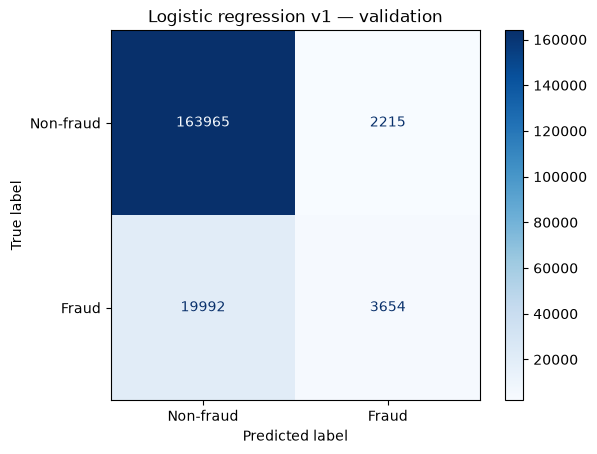

In [6]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)

threshold = 0.5  # Provisional baseline threshold.

# Get the probability assigned to the fraud class.
fraud_column = list(classifier.classes_).index(1)
validation_probabilities = baseline_model.predict_proba(
    X.loc[validation_index]
)[:, fraud_column]

validation_predictions = (
    validation_probabilities >= threshold
).astype(int)

y_validation = y.loc[validation_index]

validation_results = pd.Series({
    "average_precision": average_precision_score(
        y_validation, validation_probabilities
    ),
    "precision": precision_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_validation, validation_predictions, zero_division=0
    ),
    "validation_fraud_rate": y_validation.mean(),
    "predicted_fraud_orders": int(validation_predictions.sum()),
    "threshold": threshold,
    "training_seconds": training_seconds,
}, name="logistic_regression_v1")

display(validation_results.to_frame())

ConfusionMatrixDisplay.from_predictions(
    y_validation,
    validation_predictions,
    labels=[0, 1],
    display_labels=["Non-fraud", "Fraud"],
    values_format="d",
    cmap="Blues",
)
plt.title("Logistic regression v1 — validation")
plt.show()

## Version 1 findings and proposed improvement

The baseline trained in 7.28 seconds using 40 solver iterations.
At threshold 0.5, validation precision was 62.26% and recall was 15.45%.
It detected 3,654 fraud orders but missed 19,992.

Version 2 will use balanced class weights to give the minority fraud class
more influence during training. All other model settings, feature preparation,
data splits and the provisional threshold remain unchanged.

The comparison will examine average precision, recall, precision, F1,
false alarms and training time. Higher recall alone will not establish
that version 2 is better overall.

In [7]:
from sklearn.metrics import confusion_matrix

weighted_model, weighted_training_seconds = train_logistic_regression(
    X.loc[train_index],
    y.loc[train_index],
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
)   

weighted_classifier = weighted_model.named_steps["classifier"]
fraud_column = list(weighted_classifier.classes_).index(1)

weighted_probabilities = weighted_model.predict_proba(
    X.loc[validation_index]
)[:, fraud_column]

weighted_predictions = (
    weighted_probabilities >= threshold
).astype(int)

weighted_results = pd.Series({
    "average_precision": average_precision_score(
        y_validation, weighted_probabilities
    ),
    "precision": precision_score(
        y_validation, weighted_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_validation, weighted_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_validation, weighted_predictions, zero_division=0
    ),
    "validation_fraud_rate": y_validation.mean(),
    "predicted_fraud_orders": int(weighted_predictions.sum()),
    "threshold": threshold,
    "training_seconds": weighted_training_seconds,
}, name="logistic_regression_v2_balanced")

display(pd.concat([validation_results, weighted_results], axis=1))

tn, fp, fn, tp = confusion_matrix(
    y_validation, weighted_predictions, labels=[0, 1]
).ravel()

print("Version 2 solver iterations:", weighted_classifier.n_iter_)
print(f"Fraud caught: {tp:,}; fraud missed: {fn:,}")
print(f"False alarms: {fp:,}; correctly cleared: {tn:,}")

,logistic_regression_v1,logistic_regression_v2_balanced
average_precision,0.445946,0.443938
precision,0.622593,0.314613
recall,0.154529,0.781824
f1,0.247603,0.448675
validation_fraud_rate,0.124567,0.124567
predicted_fraud_orders,5869.000000,58761.000000
threshold,0.500000,0.500000
training_seconds,6.047773,6.819243


Version 2 solver iterations: [66]
Fraud caught: 18,487; fraud missed: 5,159
False alarms: 40,274; correctly cleared: 125,906


## Version 2 comparison

Balanced class weighting increased validation recall from 15.45% to 78.18%
and F1 from 0.2476 to 0.4487 at threshold 0.5. However, precision fell
from 62.26% to 31.46%, and false alarms increased from 2,215 to 40,274.
Average precision decreased slightly from 0.4459 to 0.4439.

Version 2 therefore improves fraud detection coverage at this threshold,
but increases review workload substantially. Compare threshold trade-offs
before selecting a model or claiming an overall improvement.

In [8]:
threshold_rows = []

for model_name, probabilities in {
    "v1": validation_probabilities,
    "v2_balanced": weighted_probabilities,
}.items():
    for candidate_threshold in [0.05, 0.10, 0.20, 0.30, 0.50, 0.70]:
        predictions = (probabilities >= candidate_threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(
            y_validation, predictions, labels=[0, 1]
        ).ravel()

        threshold_rows.append({
            "model": model_name,
            "threshold": candidate_threshold,
            "precision": precision_score(
                y_validation, predictions, zero_division=0
            ),
            "recall": recall_score(
                y_validation, predictions, zero_division=0
            ),
            "f1": f1_score(
                y_validation, predictions, zero_division=0
            ),
            "false_alarms": fp,
            "fraud_missed": fn,
            "review_percentage": 100 * predictions.mean(),
        })

threshold_comparison = pd.DataFrame(threshold_rows)
display(threshold_comparison.round(4))

,model,threshold,precision,recall,f1,false_alarms,fraud_missed,review_percentage
0,v1,0.05,0.1822,0.9220,0.3043,97850,1845,63.0319
1,v1,0.10,0.2732,0.8325,0.4114,52373,3961,37.9600
2,v1,0.20,0.4258,0.5684,0.4869,18125,10205,16.6289
3,v1,0.30,0.5360,0.3605,0.4311,7379,15121,8.3782
4,v1,0.50,0.6226,0.1545,0.2476,2215,19992,3.0918
5,v1,0.70,0.6604,0.0699,0.1264,850,21993,1.3186
6,v2_balanced,0.05,0.1246,1.0000,0.2215,166180,0,100.0000
7,v2_balanced,0.10,0.1258,0.9992,0.2234,164209,20,98.9511
8,v2_balanced,0.20,0.1520,0.9609,0.2624,126796,924,78.7658
9,v2_balanced,0.30,0.1966,0.9106,0.3234,87999,2114,57.7007


## Provisional model selection

Version 1 has slightly higher validation average precision than version 2
(0.4459 versus 0.4439), and a shorter training time.

Among the tested thresholds, version 1 at 0.20 achieved the highest
validation F1 (0.4869), with precision 42.58%, recall 56.84% and a review
rate of 16.63%.

Balanced class weighting increased recall at threshold 0.5, but did not
improve average precision and substantially increased false alarms.

Retain version 1 as the provisional candidate. Confirm the selection metric,
operating threshold and acceptable review workload with the team before
final test evaluation. No test performance has been inspected.

In [10]:
results_dir = project_root / "reports" / "brayden_logistic_regression"
results_dir.mkdir(parents=True, exist_ok=True)

pd.concat(
    [validation_results, weighted_results], axis=1
).to_csv(results_dir / "version_comparison.csv")

threshold_comparison.to_csv(
    results_dir / "validation_threshold_comparison.csv",
    index=False,
)

split_summary.to_csv(
    results_dir / "split_summary.csv",
    index=False,
)

print("Results saved to:", results_dir)

Results saved to: c:\Users\Student\OneDrive - Singapore Polytechnic\Desktop\AMLOP\AMLOP_CA1_Group2\reports\brayden_logistic_regression


## Connect to shared MLflow

Load the tracking URI from external configuration and make a read-only
request to the server before uploading experiments.

In [13]:
import os

# Keep troubleshooting requests short and disable automatic retries.
os.environ["MLFLOW_HTTP_REQUEST_TIMEOUT"] = "10"
os.environ["MLFLOW_HTTP_REQUEST_MAX_RETRIES"] = "0"

from config import configure_mlflow
from mlflow.tracking import MlflowClient
from mlflow.exceptions import MlflowException

tracking_uri = configure_mlflow()
client = MlflowClient(tracking_uri=tracking_uri)

mlflow_connected = False

try:
    client.search_experiments(max_results=1)
    mlflow_connected = True
    print("SUCCESS: MLflow tracking API responded.")
except MlflowException as exc:
    print("FAILED: MLflow connection check.")
    print(str(exc)[:500])

FAILED: MLflow connection check.
API request to http://group2-mlflow-isabelle.us-east-1.elasticbeanstalk.com/api/2.0/mlflow/experiments/search failed with timeout exception HTTPConnectionPool(host='group2-mlflow-isabelle.us-east-1.elasticbeanstalk.com', port=80): Max retries exceeded with url: /api/2.0/mlflow/experiments/search (Caused by ConnectTimeoutError(<HTTPConnection(host='group2-mlflow-isabelle.us-east-1.elasticbeanstalk.com', port=80) at 0x1e796c73350>, 'Connection to group2-mlflow-isabelle.us-east-1.elasticbeanstalk.c
